In [1]:

# TECH CHALLENGE - FASE 1
# Etapa 3: Analise exploratoria dos dados

from pathlib import Path
import pandas as pd

print("Diretorio atual:", Path.cwd())
print("Versao do Pandas:", pd.__version__)


Diretorio atual: c:\Users\Cliente\Projetos\tech-challenge-fase1\notebooks
Versao do Pandas: 3.1.0


In [2]:

# Localizar o arquivo de dados medicos

caminhos = [
    Path("data/raw/wdbc.data"),
    Path("../data/raw/wdbc.data"),
    Path("tech-challenge-fase1/data/raw/wdbc.data")
]

arquivo = next(
    (caminho for caminho in caminhos if caminho.is_file()),
    None
)

if arquivo is None:
    raise FileNotFoundError(
        "O arquivo wdbc.data nao foi encontrado."
    )

# Carregar os dados com Pandas
df = pd.read_csv(arquivo, header=None)

print("Dataset carregado com sucesso!")
print("Dimensoes:", df.shape)

# Exibir as cinco primeiras linhas
display(df.head())


Dataset carregado com sucesso!
Dimensoes: (569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:

# ETAPA 3 - Identificacao das variaveis
# Nomes das dez caracteristicas dos nucleos celulares

caracteristicas = [
    "radius",
    "texture",
    "perimeter",
    "area",
    "smoothness",
    "compactness",
    "concavity",
    "concave_points",
    "symmetry",
    "fractal_dimension"
]

# Cada caracteristica possui tres medidas estatisticas
medidas = ["mean", "se", "worst"]

# Construir a lista completa de nomes das colunas
colunas = ["id", "diagnosis"]

for medida in medidas:
    for caracteristica in caracteristicas:
        colunas.append(f"{caracteristica}_{medida}")

# Verificar se a quantidade de nomes corresponde ao dataset
assert len(colunas) == df.shape[1], (
    "A quantidade de colunas nao corresponde ao dataset."
)

# Atribuir os nomes ao DataFrame
df.columns = colunas

print("Total de colunas:", len(df.columns))
print("Dimensoes:", df.shape)

# Visualizar os primeiros registros
display(df.head())


Total de colunas: 32
Dimensoes: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



## Identificação e organização das variáveis

O conjunto Breast Cancer Wisconsin Diagnostic contém
569 amostras e 32 colunas.

As duas primeiras colunas representam o identificador
da amostra e o diagnóstico.

As outras 30 colunas correspondem a características
morfológicas dos núcleos celulares, organizadas em
três grupos: média, erro-padrão e maiores valores.

Nesta etapa, foram atribuídos nomes descritivos às
colunas para facilitar a análise exploratória e a
interpretação dos resultados.

In [4]:

# ETAPA 3 - Verificacao dos tipos de dados

print("=== INFORMACOES DO DATASET ===")

df.info()


=== INFORMACOES DO DATASET ===
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perime

In [5]:

# ETAPA 3 - Identificacao de valores ausentes

print("=== VALORES AUSENTES ===")

valores_ausentes = df.isnull().sum()

print(valores_ausentes.to_string())

print("\nTotal de valores ausentes:")
print(valores_ausentes.sum())


=== VALORES AUSENTES ===
id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0

Total de valores ausentes:
0


### Verificação da estrutura e qualidade dos dados

Após o carregamento do conjunto Breast Cancer Wisconsin Diagnostic, foram identificados 569 registros e 32 colunas, incluindo identificador, diagnóstico e 30 características numéricas.

Para verificar a estrutura da base e a qualidade inicial dos dados, foram utilizados os métodos `info()` e `isnull()` da biblioteca Pandas.

Essas verificações permitem identificar os tipos de dados, a quantidade de registros não nulos e a eventual necessidade de tratamento de valores ausentes.

Os resultados específicos dessa análise serão incorporados após a execução e conferência das verificações.

### Análise inicial da qualidade dos dados

Foi realizada uma análise inicial do conjunto Breast Cancer Wisconsin Diagnostic utilizando a biblioteca Pandas.

A partir do método `info()`, foram identificados 569 registros e 32 colunas, distribuídas entre um identificador, uma variável categórica de diagnóstico e 30 características numéricas representadas pelo tipo `float64`.

Posteriormente, foi realizada a verificação de valores ausentes por meio dos métodos `isnull()` e `sum()`.

Os resultados demonstraram que não existem valores nulos detectados nas 32 colunas analisadas.

Dessa forma, não foi identificada a necessidade inicial de técnicas de imputação de dados ausentes. Entretanto, verificações complementares serão realizadas para investigar possíveis inconsistências e registros duplicados antes da etapa de modelagem.

In [6]:

# ETAPA 3 - Distribuicao dos diagnosticos

print("=== DISTRIBUICAO DOS DIAGNOSTICOS ===")

# Contar quantas amostras pertencem a cada classe
contagem = df["diagnosis"].value_counts()

print("\nQuantidade de amostras:")
print(contagem)

# Calcular a porcentagem de cada classe
percentuais = (
    df["diagnosis"].value_counts(normalize=True) * 100
)

print("\nPercentual de cada classe:")
print(percentuais.round(2))

# Verificar a existencia de categorias inesperadas
classes_validas = {"B", "M"}
classes_encontradas = set(df["diagnosis"].unique())

print("\nCategorias encontradas:")
print(classes_encontradas)

assert classes_encontradas == classes_validas, (
    "Foram encontradas categorias inesperadas!"
)


=== DISTRIBUICAO DOS DIAGNOSTICOS ===

Quantidade de amostras:
diagnosis
B    357
M    212
Name: count, dtype: int64

Percentual de cada classe:
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64

Categorias encontradas:
{'M', 'B'}


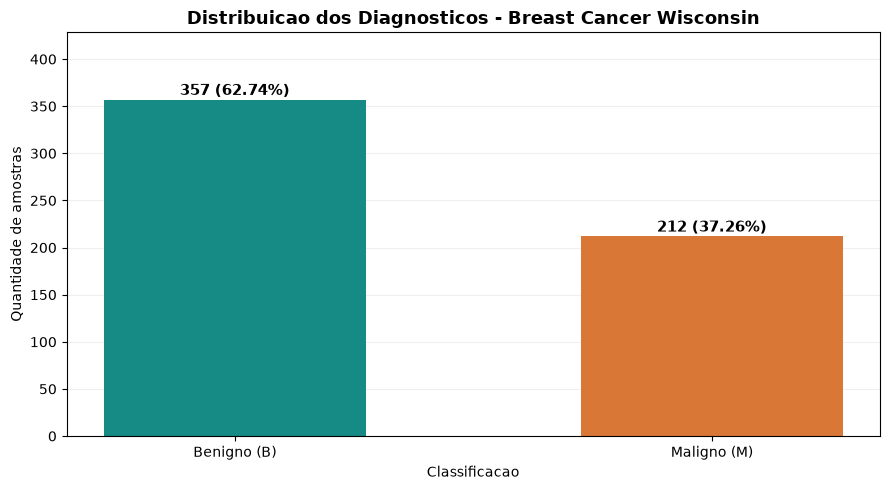

Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\01_distribuicao_diagnosticos.png


In [7]:

# ETAPA 3 - Grafico de distribuicao dos diagnosticos

import matplotlib.pyplot as plt
from pathlib import Path

# Definir a ordem das classificacoes
ordem = ["B", "M"]

# Contar as amostras de cada classe
quantidades = df["diagnosis"].value_counts().reindex(ordem)

# Calcular os percentuais
percentuais = quantidades / len(df) * 100

# Criar a figura e os eixos
fig, ax = plt.subplots(figsize=(9, 5))

# Criar as barras
barras = ax.bar(
    ["Benigno (B)", "Maligno (M)"],
    quantidades.values,
    color=["#168B85", "#D97736"],
    width=0.55
)

# Exibir quantidade e percentual acima das barras
for barra, quantidade, percentual in zip(
    barras, quantidades.values, percentuais.values
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 5,
        f"{quantidade} ({percentual:.2f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Configurar o grafico
ax.set_title(
    "Distribuicao dos Diagnosticos - Breast Cancer Wisconsin",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Classificacao")
ax.set_ylabel("Quantidade de amostras")
ax.set_ylim(0, max(quantidades) * 1.2)

# Adicionar linhas de referencia
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Ajustar espacos
plt.tight_layout()

# Localizar a pasta principal do projeto
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

# Criar a pasta de figuras, caso necessario
pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# Salvar o grafico em alta resolucao
arquivo_grafico = pasta_figuras / "01_distribuicao_diagnosticos.png"
fig.savefig(arquivo_grafico, dpi=300, bbox_inches="tight")

# Mostrar o grafico no notebook
plt.show()

print("Grafico salvo em:", arquivo_grafico)


### Distribuição das classes de diagnóstico

A análise exploratória do conjunto Breast Cancer Wisconsin Diagnostic identificou 569 amostras, distribuídas entre 357 classificações benignas (62,74%) e 212 classificações malignas (37,26%).

Observou-se uma distribuição desigual das classes, com predominância de amostras benignas.

Essa característica deverá ser considerada nas etapas de treinamento e avaliação dos algoritmos, uma vez que a acurácia isoladamente pode não representar adequadamente a capacidade do modelo de identificar amostras malignas.

Dessa forma, será dada atenção especial ao recall da classe maligna, além das métricas de precision, F1-score e matriz de confusão.

**Figura 1 — Distribuição das amostras por classificação diagnóstica.**

Fonte: elaboração própria a partir do conjunto Breast Cancer Wisconsin Diagnostic.

In [8]:

# ETAPA 3 - Verificacao de registros duplicados

print("=== ANALISE DE DUPLICATAS ===")

# 1. Verificar linhas completamente iguais
duplicatas_completas = df.duplicated().sum()

print("Duplicatas completas:", duplicatas_completas)

# 2. Verificar duplicatas ignorando o identificador
colunas_sem_id = df.columns.drop("id")

duplicatas_sem_id = df.duplicated(
    subset=colunas_sem_id
).sum()

print("Duplicatas sem considerar o ID:", duplicatas_sem_id)

# 3. Verificar identificadores repetidos
ids_repetidos = df["id"].duplicated().sum()

print("Identificadores repetidos:", ids_repetidos)

# 4. Apresentar um resumo
print("\n=== RESUMO DA VERIFICACAO ===")

if (
    duplicatas_completas == 0
    and duplicatas_sem_id == 0
    and ids_repetidos == 0
):
    print("Nenhuma duplicata identificada nas verificacoes.")
else:
    print("Foram encontradas repeticoes que precisam ser investigadas.")


=== ANALISE DE DUPLICATAS ===
Duplicatas completas: 0
Duplicatas sem considerar o ID: 0
Identificadores repetidos: 0

=== RESUMO DA VERIFICACAO ===
Nenhuma duplicata identificada nas verificacoes.


### Verificação de registros duplicados

Nesta etapa, foi realizada uma investigação de possíveis registros duplicados no conjunto de dados.

Foram considerados três critérios de análise: duplicação integral das linhas, repetição de características e diagnósticos desconsiderando o identificador e existência de identificadores repetidos.

O objetivo dessa verificação é identificar possíveis redundâncias e avaliar a necessidade de tratamento antes do treinamento dos algoritmos de Machine Learning.

A decisão sobre eventual remoção de registros será tomada após a interpretação dos resultados encontrados.

In [9]:

# ETAPA 3 - Verificacao de inconsistencias numericas

import numpy as np

print("=== VERIFICACAO DE CONSISTENCIA NUMERICA ===")

# Selecionar somente as 30 caracteristicas preditoras
atributos = df.drop(columns=["id", "diagnosis"])

print("\nQuantidade de atributos:", atributos.shape[1])

# 1. Verificar valores nao finitos (NaN e infinitos)
valores_nao_finitos = (
    ~np.isfinite(atributos.to_numpy())
).sum()

print("Valores nao finitos:", valores_nao_finitos)

# 2. Verificar valores negativos
valores_negativos = (atributos < 0).sum().sum()

print("Valores negativos:", valores_negativos)

# 3. Contar valores iguais a zero
valores_zero = (atributos == 0).sum().sum()

print("Valores iguais a zero:", valores_zero)

# 4. Apresentar conclusao
print("\n=== RESULTADO ===")

if valores_nao_finitos == 0 and valores_negativos == 0:
    print("Nenhum valor nao finito ou negativo identificado.")
else:
    print("Foram encontrados valores que exigem investigacao.")

print("Observacao: valores zero nao sao necessariamente erros.")


=== VERIFICACAO DE CONSISTENCIA NUMERICA ===

Quantidade de atributos: 30
Valores nao finitos: 0
Valores negativos: 0
Valores iguais a zero: 78

=== RESULTADO ===
Nenhum valor nao finito ou negativo identificado.
Observacao: valores zero nao sao necessariamente erros.


In [10]:

# ETAPA 3 - Analise dos valores iguais a zero

print("=== ANALISE DOS VALORES ZERO ===")

# Contar valores zero em cada atributo
zeros_por_coluna = (atributos == 0).sum()

# Selecionar somente os atributos que possuem zeros
colunas_com_zeros = zeros_por_coluna[
    zeros_por_coluna > 0
]

# Ordenar do maior para o menor
colunas_com_zeros = colunas_com_zeros.sort_values(
    ascending=False
)

# Criar tabela de resultados
tabela_zeros = pd.DataFrame({
    "Quantidade de zeros": colunas_com_zeros,
    "Percentual (%)": (
        colunas_com_zeros / len(df) * 100
    ).round(2)
})

print("\nCaracteristicas com valores zero:")
display(tabela_zeros)

print("\nTotal de valores zero:")
print(colunas_com_zeros.sum())


=== ANALISE DOS VALORES ZERO ===

Caracteristicas com valores zero:


,Quantidade de zeros,Percentual (%)
concavity_mean,13,2.28
concave_points_mean,13,2.28
concavity_se,13,2.28
concave_points_se,13,2.28
concavity_worst,13,2.28
concave_points_worst,13,2.28



Total de valores zero:
78


### Verificação de consistência numérica

Foram analisadas as 30 características numéricas do conjunto Breast Cancer Wisconsin Diagnostic, com o objetivo de identificar valores ausentes, não finitos, negativos e iguais a zero.

Não foram identificados valores ausentes, não finitos ou negativos. Entretanto, foram encontradas 78 ocorrências de valores iguais a zero, distribuídas igualmente entre seis características relacionadas à concavidade e aos pontos côncavos dos núcleos celulares.

Cada uma dessas características apresentou 13 ocorrências, correspondentes a aproximadamente 2,28% das amostras.

Considerando a natureza das medidas morfológicas, os valores iguais a zero foram considerados potencialmente válidos e preservados nesta fase da análise, evitando a aplicação de tratamentos desnecessários.

Essa decisão poderá ser revisada caso as verificações posteriores identifiquem evidências de inconsistência.

In [11]:

# ETAPA 3 - Estatistica descritiva

print("=== ESTATISTICAS DESCRITIVAS ===")

# Selecionar as 30 caracteristicas numericas
# Excluimos ID e diagnostico
atributos = df.drop(columns=["id", "diagnosis"])

# Calcular as estatisticas descritivas
estatisticas = atributos.describe().T

# Renomear as colunas para facilitar a interpretacao
estatisticas = estatisticas.rename(columns={
    "count": "quantidade",
    "mean": "media",
    "std": "desvio_padrao",
    "min": "minimo",
    "25%": "Q1",
    "50%": "mediana",
    "75%": "Q3",
    "max": "maximo"
})

# Exibir resultados com 3 casas decimais
display(estatisticas.round(3))

print("\nTotal de caracteristicas analisadas:")
print(len(estatisticas))


=== ESTATISTICAS DESCRITIVAS ===


,quantidade,media,desvio_padrao,minimo,Q1,mediana,Q3,maximo
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097



Total de caracteristicas analisadas:
30


In [12]:

# ETAPA 3 - Comparacao entre diagnosticos
# Benigno (B) e Maligno (M)

print("=== COMPARACAO ENTRE DIAGNOSTICOS ===")

# Selecionar quatro caracteristicas para analise
variaveis_selecionadas = [
    "radius_mean",
    "area_mean",
    "concavity_mean",
    "concave_points_mean"
]

# Agrupar as amostras pelo diagnostico
# e calcular a media de cada caracteristica
comparacao_medias = (
    df.groupby("diagnosis")[variaveis_selecionadas]
    .mean()
    .reindex(["B", "M"])
    .round(3)
)

# Substituir os codigos por nomes descritivos
comparacao_medias = comparacao_medias.rename(
    index={
        "B": "Benigno (B)",
        "M": "Maligno (M)"
    }
)

print("\nMedia das caracteristicas por diagnostico:")

display(comparacao_medias)


=== COMPARACAO ENTRE DIAGNOSTICOS ===

Media das caracteristicas por diagnostico:


,radius_mean,area_mean,concavity_mean,concave_points_mean
diagnosis,,,,
Benigno (B),12.147,462.790,0.046,0.026
Maligno (M),17.463,978.376,0.161,0.088


Análise comparativa das características morfológicas

Após o cálculo das estatísticas descritivas gerais, foi definida uma análise comparativa das características dos núcleos celulares em função do diagnóstico.

Para essa investigação, serão consideradas inicialmente as variáveis relacionadas ao raio, à área e às medidas de concavidade.

O objetivo é identificar diferenças nos padrões estatísticos entre amostras benignas e malignas, fornecendo subsídios para a interpretação dos dados e para as etapas posteriores de modelagem.

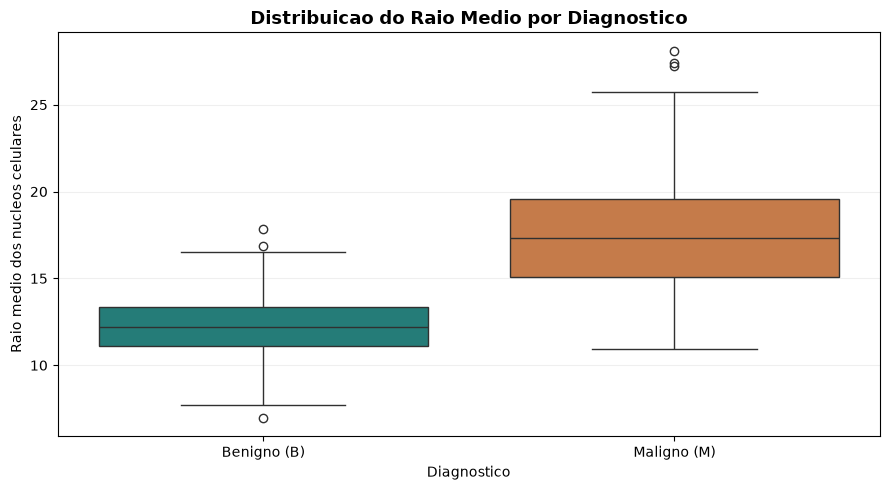

Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\02_boxplot_raio_diagnostico.png


In [13]:

# ETAPA 3 - Boxplot do raio medio por diagnostico

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Criar a figura
fig, ax = plt.subplots(figsize=(9, 5))

# Construir o boxplot
sns.boxplot(
    data=df,
    x="diagnosis",
    y="radius_mean",
    order=["B", "M"],
    hue="diagnosis",
    palette={
        "B": "#168B85",
        "M": "#D97736"
    },
    dodge=False,
    legend=False,
    ax=ax
)

# Configurar o grafico
ax.set_title(
    "Distribuicao do Raio Medio por Diagnostico",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Diagnostico")
ax.set_ylabel("Raio medio dos nucleos celulares")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Benigno (B)", "Maligno (M)"])

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Identificar a pasta principal do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Criar a pasta para salvar o grafico
pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# Salvar a figura
arquivo = pasta_figuras / "02_boxplot_raio_diagnostico.png"

fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

# Mostrar o grafico
plt.show()

print("Grafico salvo em:", arquivo)


### Análise comparativa das características morfológicas

A análise comparativa das médias das características morfológicas revelou diferenças entre as amostras benignas e malignas.

Para a variável `radius_mean`, foram observadas médias de 12,147 nas amostras benignas e 17,463 nas malignas.

Em relação à variável `area_mean`, as médias foram de 462,790 e 978,376, respectivamente.

As características relacionadas à concavidade também apresentaram médias superiores no grupo maligno. Para `concavity_mean`, os valores foram de 0,046 e 0,161, enquanto para `concave_points_mean` foram de 0,026 e 0,088.

Esses resultados indicam diferenças descritivas nas características dos dois grupos e justificam o aprofundamento da análise por meio de visualizações estatísticas.

Ressalta-se que diferenças entre médias não são suficientes para determinar a capacidade de classificação de uma variável. Para isso, serão investigadas a dispersão, a sobreposição das distribuições e, posteriormente, as métricas dos modelos preditivos.

### Análise da distribuição do raio médio por diagnóstico

A distribuição da variável `radius_mean` foi investigada por meio de um boxplot, considerando separadamente as amostras classificadas como benignas e malignas.

Observou-se que as amostras malignas apresentam valores centrais de raio médio superiores aos das amostras benignas, além de maior dispersão na região interquartil.

Embora as regiões centrais das distribuições estejam visualmente separadas, foram identificados intervalos de valores compartilhados entre os grupos, indicando sobreposição parcial.

Também foram observados possíveis valores extremos em ambas as classes. Esses registros não foram removidos, pois sua identificação pelo boxplot não constitui, isoladamente, evidência de inconsistência.

Os resultados sugerem que o raio médio dos núcleos celulares pode fornecer informação relevante para a classificação. Entretanto, sua contribuição preditiva deverá ser avaliada em conjunto com outras características e com os resultados dos modelos de Machine Learning.

**Figura 2 — Distribuição do raio médio dos núcleos celulares por diagnóstico.**

Fonte: elaboração própria a partir do dataset Breast Cancer Wisconsin Diagnostic.

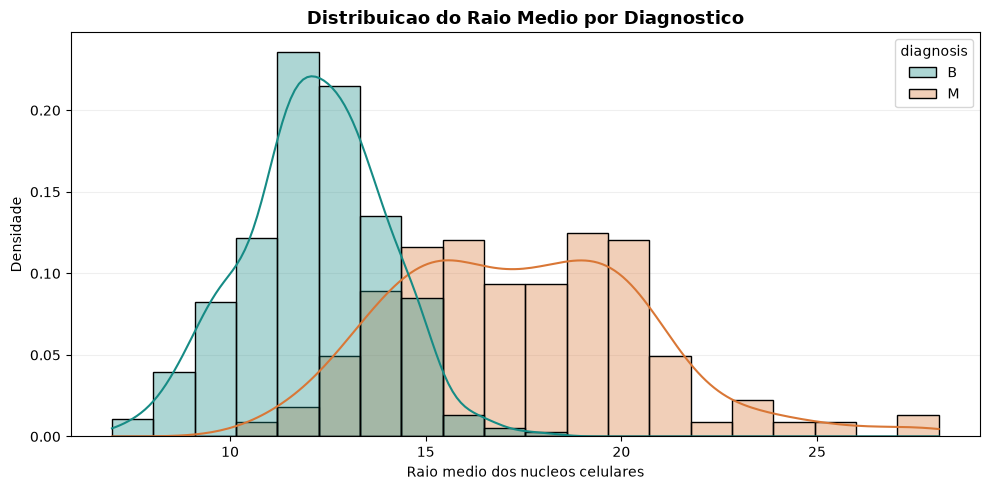

Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\03_histograma_raio_diagnostico.png


In [14]:

# ETAPA 3 - Histograma comparativo do raio medio

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Criar figura
fig, ax = plt.subplots(figsize=(10, 5))

# Construir histograma por diagnostico
sns.histplot(
    data=df,
    x="radius_mean",
    hue="diagnosis",
    hue_order=["B", "M"],
    palette={
        "B": "#168B85",
        "M": "#D97736"
    },
    bins=20,
    stat="density",
    common_norm=False,
    kde=True,
    alpha=0.35,
    ax=ax
)

# Configuracoes visuais
ax.set_title(
    "Distribuicao do Raio Medio por Diagnostico",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Raio medio dos nucleos celulares")
ax.set_ylabel("Densidade")

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Preparar o diretorio
pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# Salvar o grafico
arquivo = pasta_figuras / "03_histograma_raio_diagnostico.png"

fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

# Exibir resultado
plt.show()

print("Grafico salvo em:", arquivo)


### Análise da distribuição do raio médio

Com o objetivo de aprofundar a investigação da variável `radius_mean`, foi construído um histograma comparativo acompanhado de curvas de densidade estimada, considerando separadamente os diagnósticos benigno e maligno.

A visualização revelou uma maior concentração das amostras benignas em valores inferiores de raio médio, enquanto as amostras malignas apresentaram distribuição mais ampla e deslocada para valores superiores.

Entretanto, observou-se sobreposição parcial entre as distribuições, indicando que o raio médio, isoladamente, não permite uma separação perfeita entre as classes.

Esses resultados reforçam a necessidade de uma abordagem multivariada, na qual diferentes características morfológicas sejam consideradas durante a construção dos modelos de classificação.

**Figura 3 — Histograma comparativo do raio médio por diagnóstico.**

Fonte: elaboração própria a partir do Breast Cancer Wisconsin Diagnostic.

## Comparação gráfica das características morfológicas

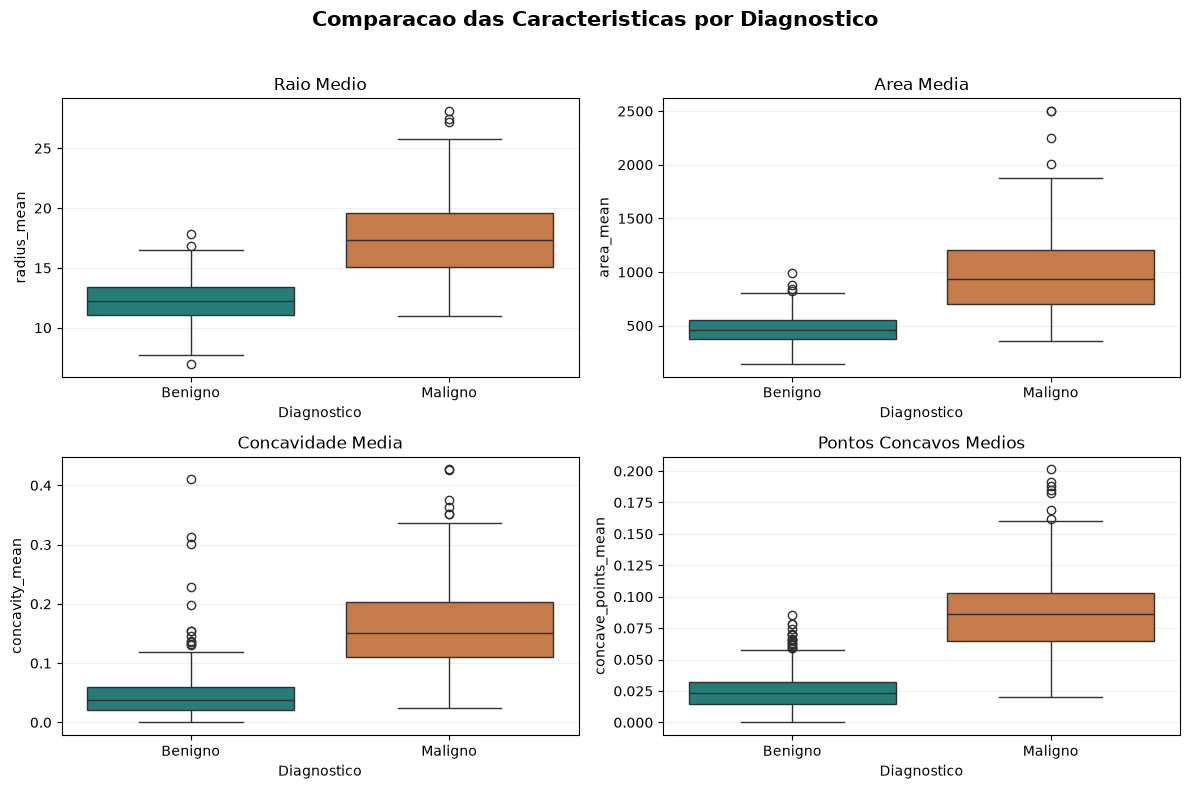

Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\04_boxplots_caracteristicas.png


In [15]:

# ETAPA 3 - Comparacao de quatro caracteristicas
# Utilizando boxplots separados por diagnostico

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Definir as caracteristicas e seus titulos
variaveis = {
    "radius_mean": "Raio Medio",
    "area_mean": "Area Media",
    "concavity_mean": "Concavidade Media",
    "concave_points_mean": "Pontos Concavos Medios"
}

# Criar quatro graficos organizados em 2 linhas e 2 colunas
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))

# Percorrer as variaveis e os eixos
for eixo, (variavel, titulo) in zip(
    eixos.flat, variaveis.items()
):

    sns.boxplot(
        data=df,
        x="diagnosis",
        y=variavel,
        order=["B", "M"],
        hue="diagnosis",
        palette={
            "B": "#168B85",
            "M": "#D97736"
        },
        dodge=False,
        legend=False,
        ax=eixo
    )

    eixo.set_title(titulo)
    eixo.set_xlabel("Diagnostico")
    eixo.set_ylabel(variavel)

    eixo.set_xticks(
        [0, 1],
        labels=["Benigno", "Maligno"]
    )

    eixo.grid(axis="y", alpha=0.2)
    eixo.set_axisbelow(True)

# Titulo geral
fig.suptitle(
    "Comparacao das Caracteristicas por Diagnostico",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Identificar a pasta do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Preparar pasta de figuras
pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# Salvar o grafico
arquivo = (
    pasta_figuras /
    "04_boxplots_caracteristicas.png"
)

fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafico salvo em:", arquivo)


### Análise comparativa das características morfológicas

Foram construídos quatro boxplots para investigar a distribuição das variáveis `radius_mean`, `area_mean`, `concavity_mean` e `concave_points_mean` em função do diagnóstico.

A análise visual revelou que as amostras malignas apresentam medianas superiores às benignas nas quatro características investigadas.

Observou-se também maior dispersão interquartil nas amostras malignas, bem como a presença de possíveis valores extremos em ambos os grupos.

Apesar das diferenças observadas, as distribuições apresentam regiões de sobreposição, indicando que nenhuma dessas características deve ser considerada individualmente suficiente para realizar uma classificação perfeita.

Os resultados justificam o aprofundamento da análise multivariada e a investigação das relações estatísticas entre as características, etapa que será realizada por meio de uma matriz de correlação.

**Figura 4 — Comparação das características morfológicas por diagnóstico.**

Fonte: elaboração própria a partir do conjunto Breast Cancer Wisconsin Diagnostic.


## Análise de correlação entre características morfológicas

A análise de correlação tem como objetivo investigar
as relações lineares entre as características
numéricas do conjunto de dados.

Inicialmente, serão consideradas quatro variáveis:
raio médio, área média, concavidade média e
pontos côncavos médios.

Será utilizado o coeficiente de correlação de Pearson,
permitindo identificar associações lineares positivas
e negativas entre essas características.


In [16]:

# ETAPA 3 - Analise de correlacao
# Pearson entre quatro caracteristicas morfologicas

variaveis_correlacao = [
    "radius_mean",
    "area_mean",
    "concavity_mean",
    "concave_points_mean"
]

# Selecionar apenas as quatro caracteristicas
dados_correlacao = df[variaveis_correlacao]

# Calcular a correlacao de Pearson
matriz_correlacao = dados_correlacao.corr(
    method="pearson"
)

print("=== MATRIZ DE CORRELACAO ===")

display(matriz_correlacao.round(3))


=== MATRIZ DE CORRELACAO ===


,radius_mean,area_mean,concavity_mean,concave_points_mean
radius_mean,1.000,0.987,0.677,0.823
area_mean,0.987,1.000,0.686,0.823
concavity_mean,0.677,0.686,1.000,0.921
concave_points_mean,0.823,0.823,0.921,1.000


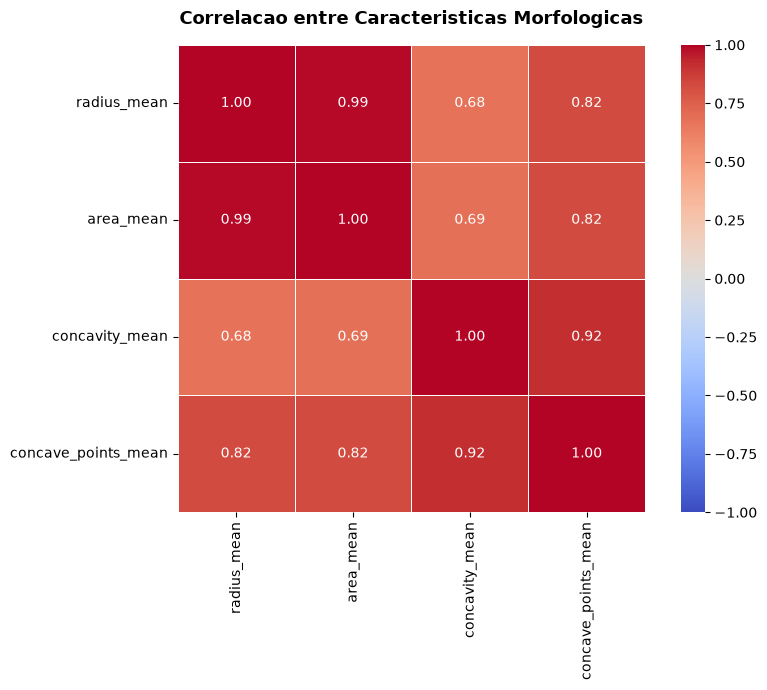

Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\05_correlacao_caracteristicas.png


In [17]:

# ETAPA 3 - Mapa de calor das correlacoes

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Criar a figura
fig, ax = plt.subplots(figsize=(9, 7))

# Construir o heatmap
sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax
)

# Configurar o titulo
ax.set_title(
    "Correlacao entre Caracteristicas Morfologicas",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

# Localizar a pasta principal do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Preparar a pasta de figuras
pasta_figuras = raiz / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# Salvar o mapa de calor
arquivo = (
    pasta_figuras /
    "05_correlacao_caracteristicas.png"
)

fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

# Exibir o grafico
plt.show()

print("Grafico salvo em:", arquivo)


### Análise de correlação entre características morfológicas

Foi realizada uma análise de correlação utilizando o coeficiente de Pearson, com o objetivo de investigar as associações lineares entre quatro características morfológicas do conjunto Breast Cancer Wisconsin Diagnostic.

Os resultados demonstraram correlações positivas entre todas as variáveis selecionadas.

A associação mais elevada foi observada entre `radius_mean` e `area_mean`, com coeficiente de 0,987, indicando uma relação linear positiva extremamente forte.

Também foi identificada uma correlação de 0,921 entre `concavity_mean` e `concave_points_mean`, sugerindo que essas variáveis apresentam informações parcialmente relacionadas.

As demais combinações apresentaram coeficientes entre 0,677 e 0,823.

Esses resultados evidenciam a importância de investigar possíveis redundâncias entre as características utilizadas na modelagem.

Entretanto, nenhuma variável foi excluída nesta etapa, uma vez que a análise de correlação isoladamente não determina sua relevância preditiva.

**Figura 5 — Matriz de correlação de Pearson entre características morfológicas selecionadas.**

Fonte: elaboração própria a partir do Breast Cancer Wisconsin Diagnostic.

In [18]:

# ETAPA 3 - Correlacao das 30 caracteristicas
# Identificacao dos pares mais correlacionados

import numpy as np
import pandas as pd

print("=== CORRELACAO DAS 30 CARACTERISTICAS ===")

# Selecionar as variaveis preditoras
variaveis_numericas = df.drop(
    columns=["id", "diagnosis"]
)

# Confirmar o numero de caracteristicas
assert variaveis_numericas.shape[1] == 30

# Calcular a matriz de Pearson
matriz_correlacao_30 = variaveis_numericas.corr(
    method="pearson"
)

print("Dimensoes da matriz:", matriz_correlacao_30.shape)

# Criar uma mascara para usar apenas os pares
# acima da diagonal principal
mascara_superior = np.triu(
    np.ones(matriz_correlacao_30.shape, dtype=bool),
    k=1
)

# Transformar os coeficientes em uma tabela
pares_correlacionados = (
    matriz_correlacao_30
    .where(mascara_superior)
    .stack()
    .dropna()
    .reset_index()
)

pares_correlacionados.columns = [
    "Variavel 1",
    "Variavel 2",
    "Correlacao"
]

# Calcular o valor absoluto da correlacao
pares_correlacionados["Correlacao absoluta"] = (
    pares_correlacionados["Correlacao"].abs()
)

# Ordenar da maior para a menor associacao
pares_correlacionados = (
    pares_correlacionados.sort_values(
        by="Correlacao absoluta",
        ascending=False
    )
)

print("\nDez pares com maior correlacao absoluta:")

display(pares_correlacionados.head(10).round(3))

print("\nTotal de pares analisados:")
print(len(pares_correlacionados))


=== CORRELACAO DAS 30 CARACTERISTICAS ===
Dimensoes da matriz: (30, 30)

Dez pares com maior correlacao absoluta:


,Variavel 1,Variavel 2,Correlacao,Correlacao absoluta
1,radius_mean,perimeter_mean,0.998,0.998
391,radius_worst,perimeter_worst,0.994,0.994
2,radius_mean,area_mean,0.987,0.987
57,perimeter_mean,area_mean,0.987,0.987
392,radius_worst,area_worst,0.984,0.984
407,perimeter_worst,area_worst,0.978,0.978
246,radius_se,perimeter_se,0.973,0.973
76,perimeter_mean,perimeter_worst,0.970,0.970
19,radius_mean,radius_worst,0.970,0.970
74,perimeter_mean,radius_worst,0.969,0.969



Total de pares analisados:
435


### Roteiro — Interpretação das correlações

**Mostrar na tela:** mapa de calor das características morfológicas.

**Fala sugerida:**

"Durante a análise de correlação, utilizamos o coeficiente de Pearson para investigar as relações lineares entre as características numéricas.

Entre as variáveis inicialmente selecionadas, identificamos uma correlação de aproximadamente 0,99 entre o raio médio e a área média dos núcleos celulares, além de uma correlação de aproximadamente 0,92 entre as medidas de concavidade e pontos côncavos.

Esses resultados sugerem que algumas variáveis podem apresentar informações parcialmente redundantes, aspecto que deverá ser considerado na interpretação e na avaliação dos modelos de Machine Learning."

## Mapa de calor completo das 30 características

Nesta etapa, será construído um mapa de calor
com os coeficientes de correlação de Pearson
entre as 30 características morfológicas.

O objetivo é identificar grupos de variáveis
fortemente associadas e investigar possíveis
relações de multicolinearidade.

A análise é exploratória e não será utilizada
isoladamente para excluir variáveis do modelo.

=== MAPA DE CALOR COMPLETO ===


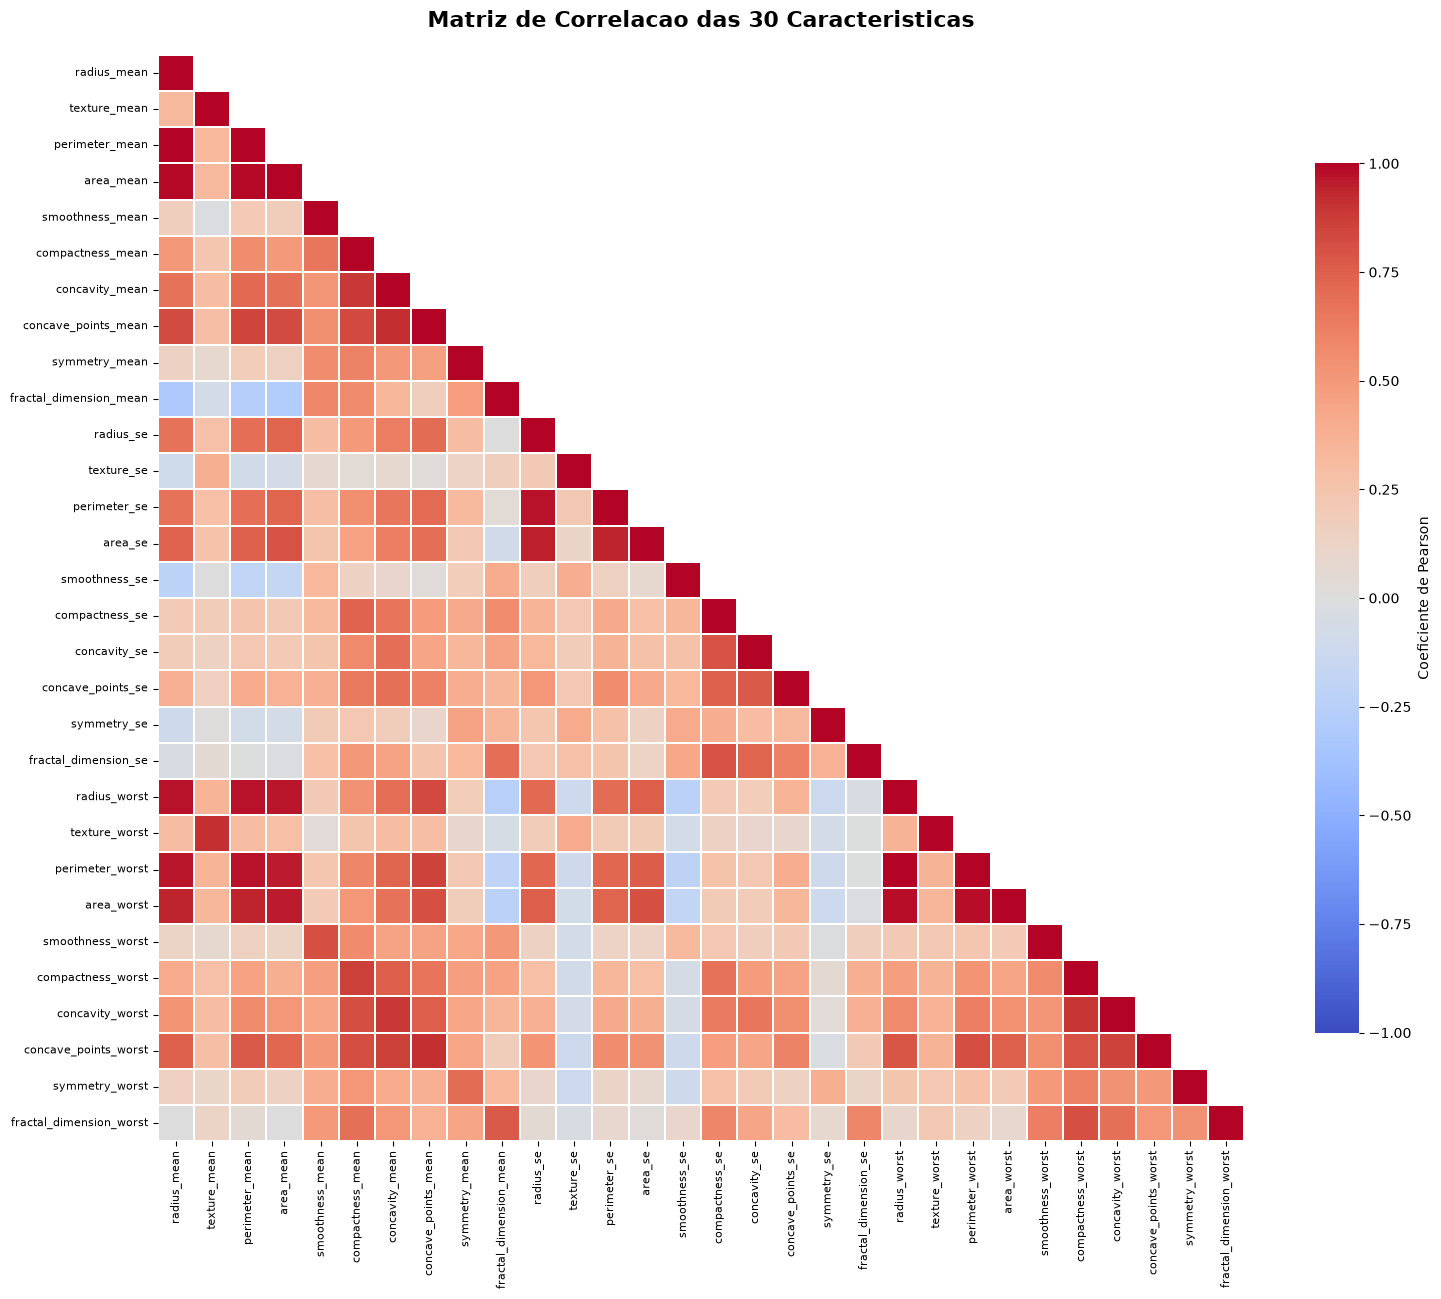

Grafico salvo em: c:\Users\Cliente\Projetos\tech-challenge-fase1\reports\figures\06_heatmap_correlacao_30_variaveis.png


In [19]:

# ETAPA 3 - Heatmap das 30 caracteristicas

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("=== MAPA DE CALOR COMPLETO ===")

# Utilizar a matriz calculada na etapa anterior
matriz = matriz_correlacao_30

# Criar mascara para ocultar a metade superior
# e manter a diagonal principal
mascara = np.triu(
    np.ones_like(matriz, dtype=bool),
    k=1
)

# Criar uma figura maior para facilitar a leitura
fig, ax = plt.subplots(figsize=(16, 13))

# Construir o mapa de calor
sns.heatmap(
    matriz,
    mask=mascara,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    square=True,
    linewidths=0.3,
    cbar_kws={
        "label": "Coeficiente de Pearson",
        "shrink": 0.8
    },
    ax=ax
)

# Configurar o titulo
ax.set_title(
    "Matriz de Correlacao das 30 Caracteristicas",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# Ajustar os nomes das variaveis
ax.tick_params(
    axis="x",
    labelrotation=90,
    labelsize=8
)

ax.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=8
)

plt.tight_layout()

# Identificar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Definir a pasta para salvar
pasta_figuras = raiz / "reports" / "figures"

pasta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

# Nome do arquivo
arquivo = (
    pasta_figuras /
    "06_heatmap_correlacao_30_variaveis.png"
)

# Salvar em alta resolucao
fig.savefig(
    arquivo,
    dpi=300,
    bbox_inches="tight"
)

# Exibir o grafico
plt.show()

print("Grafico salvo em:", arquivo)


### Análise de correlação das 30 características

A análise de correlação foi ampliada para as 30 características numéricas do conjunto Breast Cancer Wisconsin Diagnostic, utilizando o coeficiente de Pearson.

Foram investigadas 435 combinações únicas de características, identificando-se associações lineares positivas e negativas de diferentes intensidades.

Entre os resultados de maior destaque, observou-se uma correlação de 0,998 entre as variáveis `radius_mean` e `perimeter_mean`, indicando associação linear positiva quase perfeita. Também foi identificada correlação de 0,994 entre `radius_worst` e `perimeter_worst`.

O mapa de calor evidenciou agrupamentos de correlações elevadas, especialmente entre características relacionadas às dimensões dos núcleos celulares.

Esses resultados sugerem a presença de informações parcialmente redundantes entre determinados atributos, aspecto que deverá ser considerado na interpretação dos modelos preditivos.

Nesta etapa, optou-se pela preservação das 30 características. Eventuais decisões de seleção de atributos serão avaliadas posteriormente, utilizando procedimentos de validação adequados e evitando vazamento de dados.

**Figura 6 — Matriz de correlação de Pearson das 30 características morfológicas.**

Fonte: elaboração própria a partir do conjunto Breast Cancer Wisconsin Diagnostic.

## Verificação final da análise exploratória

Nesta seção serão verificadas a integridade do dataset,
as dimensões da matriz de correlação e a existência
dos gráficos produzidos durante a análise.

O objetivo é confirmar que os resultados necessários
para o relatório e a apresentação foram gerados.

In [20]:

# ETAPA 3 - Validacao final da analise exploratoria

from pathlib import Path
import numpy as np

print("=== VALIDACAO FINAL DA ETAPA 3 ===")

# 1. Verificar estrutura do dataset
assert df.shape == (569, 32), "Dimensoes incorretas!"

print("Dataset: 569 amostras e 32 colunas - OK")

# 2. Verificar distribuicao dos diagnosticos
assert (df["diagnosis"] == "B").sum() == 357
assert (df["diagnosis"] == "M").sum() == 212

print("Distribuicao das classes - OK")

# 3. Verificar valores ausentes
assert df.isnull().sum().sum() == 0

print("Valores ausentes - OK")

# 4. Verificar duplicatas
assert df.duplicated().sum() == 0
assert df.duplicated(
    subset=df.columns.drop("id")
).sum() == 0
assert df["id"].duplicated().sum() == 0

print("Verificacao de duplicatas - OK")

# 5. Verificar consistencia das 30 caracteristicas
atributos_validacao = df.drop(
    columns=["id", "diagnosis"]
)

assert np.isfinite(
    atributos_validacao.to_numpy()
).all()

assert (atributos_validacao >= 0).all().all()

print("Consistencia numerica - OK")

# 6. Verificar matriz de correlacao
assert matriz_correlacao_30.shape == (30, 30)

print("Matriz de correlacao - OK")

# 7. Verificar os graficos
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

pasta_figuras = raiz / "reports" / "figures"

arquivos = [
    "01_distribuicao_diagnosticos.png",
    "02_boxplot_raio_diagnostico.png",
    "03_histograma_raio_diagnostico.png",
    "04_boxplots_caracteristicas.png",
    "05_correlacao_caracteristicas.png",
    "06_heatmap_correlacao_30_variaveis.png"
]

for nome in arquivos:
    caminho = pasta_figuras / nome
    assert caminho.is_file(), (
        f"Grafico nao encontrado: {nome}"
    )
    print("Grafico encontrado:", nome)

print("\nETAPA 3 VALIDADA COM SUCESSO!")


=== VALIDACAO FINAL DA ETAPA 3 ===
Dataset: 569 amostras e 32 colunas - OK
Distribuicao das classes - OK
Valores ausentes - OK
Verificacao de duplicatas - OK
Consistencia numerica - OK
Matriz de correlacao - OK
Grafico encontrado: 01_distribuicao_diagnosticos.png
Grafico encontrado: 02_boxplot_raio_diagnostico.png
Grafico encontrado: 03_histograma_raio_diagnostico.png
Grafico encontrado: 04_boxplots_caracteristicas.png
Grafico encontrado: 05_correlacao_caracteristicas.png
Grafico encontrado: 06_heatmap_correlacao_30_variaveis.png

ETAPA 3 VALIDADA COM SUCESSO!
